<a href="https://colab.research.google.com/github/oliver4701/pytorch_tutorials/blob/CoLab/glove-word-vectors/glove-word-vectors%20EXTENDED.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![](https://i.imgur.com/eBRPvWB.png)

# Practical PyTorch: Exploring Word Vectors with GloVe

When working with words, dealing with the huge but sparse domain of language can be challenging. Even for a small corpus, your neural network (or any type of model) needs to support many thousands of discrete inputs and outputs.

Besides the raw number words, the standard technique of representing words as one-hot vectors (e.g. "the" = `[0 0 0 1 0 0 0 0 ...]`) does not capture any information about relationships between words.

Word vectors address this problem by representing words in a multi-dimensional vector space. This can bring the dimensionality of the problem from hundreds-of-thousands to just hundreds. Plus, the vector space is able to capture semantic relationships between words in terms of distance and vector arithmetic.

![](https://i.imgur.com/y4hG1ak.png)

There are a few techniques for creating word vectors. The word2vec algorithm predicts words in a context (e.g. what is the most likely word to appear in "the cat ? the mouse"), while GloVe vectors are based on global counts across the corpus &mdash; see [How is GloVe different from word2vec?](https://www.quora.com/How-is-GloVe-different-from-word2vec) on Quora for some better explanations.

In my opinion the best feature of GloVe is that multiple sets of pre-trained vectors are easily [available for download](https://nlp.stanford.edu/projects/glove/), so that's what we'll use here.

## Recommended reading

* https://blog.acolyer.org/2016/04/21/the-amazing-power-of-word-vectors/
* https://blog.acolyer.org/2016/04/22/glove-global-vectors-for-word-representation/
* https://levyomer.wordpress.com/2014/04/25/linguistic-regularities-in-sparse-and-explicit-word-representations/

## Installing torchtext

The torchtext package is not currently on the PIP or Conda package managers, but it's easy to install manually:

```
git clone https://github.com/pytorch/text pytorch-text
cd pytorch-text
python setup.py install
```

## Loading word vectors

Torchtext includes functions to download GloVe (and other) embeddings

In [2]:
!pip install torchtext
import torch
import torchtext.vocab as vocab

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.2/64.2 kB 3.4 MB/s eta 0:00:00


In [3]:
glove = vocab.GloVe(name='6B', dim=100)

print('Loaded {} words'.format(len(glove.itos)))

.vector_cache/glove.6B.zip: 862MB [04:29, 3.20MB/s]                           
100%|█████████▉| 399999/400000 [00:24<00:00, 16077.06it/s]


Loaded 400000 words


The returned `GloVe` object includes attributes:
- `stoi` _string-to-index_ returns a dictionary of words to indexes
- `itos` _index-to-string_ returns an array of words by index
- `vectors` returns the actual vectors. To get a word vector get the index to get the vector:

In [4]:
def get_word(word):
    return glove.vectors[glove.stoi[word]]

In [11]:
# 1. Find the index of the word
word = "apple"
word_idx = glove.stoi[word]

# 2. Access the vector using the index
word_vector = glove.vectors[word_idx]

print(f"Word: {word}")
print(f"Index: {word_idx}")
print(f"Vector shape: {word_vector.shape}")
print(f"Vector values (first 5 elements): {word_vector[:5]}")

Word: apple
Index: 3292
Vector shape: torch.Size([100])
Vector values (first 5 elements): tensor([-0.5985, -0.4632,  0.1300, -0.0196,  0.4603])


## Finding closest vectors

Going from word &rarr; vector is easy enough, but to go from vector &rarr; word takes more work. Here I'm (naively) calculating the distance for each word in the vocabulary, and sorting based on that distance:

Anyone with a suggestion for optimizing this, please let me know!

In [5]:
def closest(vec, n=10):
    """
    Find the closest words for a given vector
    """
    all_dists = [(w, torch.dist(vec, get_word(w))) for w in glove.itos]
    return sorted(all_dists, key=lambda t: t[1])[:n]

This will return a list of `(word, distance)` tuple pairs. Here's a helper function to print that list:

In [6]:
def print_tuples(tuples):
    for tuple in tuples:
        print('(%.4f) %s' % (tuple[1], tuple[0]))

Now using a known word vector we can see which other vectors are closest:

In [7]:
print_tuples(closest(get_word('google')))

(0.0000) google
(3.0772) yahoo
(3.8836) microsoft
(4.1048) web
(4.1082) aol
(4.1165) facebook
(4.3917) ebay
(4.4122) msn
(4.4540) internet
(4.4651) netscape


## Word analogies with vector arithmetic

The most interesting feature of a well-trained word vector space is that certain semantic relationships (beyond just close-ness of words) can be captured with regular vector arithmetic.

![](https://i.imgur.com/d0KuM5x.png)

(image borrowed from [a slide from Omer Levy and Yoav Goldberg](https://levyomer.wordpress.com/2014/04/25/linguistic-regularities-in-sparse-and-explicit-word-representations/))

In [8]:
# In the form w1 : w2 :: w3 : ?
def analogy(w1, w2, w3, n=5, filter_given=True):
    print('\n[%s : %s :: %s : ?]' % (w1, w2, w3))

    # w2 - w1 + w3 = w4
    closest_words = closest(get_word(w2) - get_word(w1) + get_word(w3))

    # Optionally filter out given words
    if filter_given:
        closest_words = [t for t in closest_words if t[0] not in [w1, w2, w3]]

    print_tuples(closest_words[:n])

The classic example:

In [9]:
analogy('king', 'man', 'queen')


[king : man :: queen : ?]
(4.0811) woman
(4.6916) girl
(5.2703) she
(5.2788) teenager
(5.3084) boy


Now let's explore the word space and see what stereotypes we can uncover:

In [10]:
analogy('man', 'actor', 'woman')
analogy('cat', 'kitten', 'dog')
analogy('dog', 'puppy', 'cat')
analogy('russia', 'moscow', 'france')
analogy('obama', 'president', 'trump')
analogy('rich', 'mansion', 'poor')
analogy('elvis', 'rock', 'eminem')
analogy('paper', 'newspaper', 'screen')
analogy('monet', 'paint', 'michelangelo')
analogy('beer', 'barley', 'wine')
analogy('earth', 'moon', 'sun') # Interesting failure mode
analogy('house', 'roof', 'castle')
analogy('building', 'architect', 'software')
analogy('boston', 'bruins', 'phoenix')
analogy('good', 'heaven', 'bad')
analogy('jordan', 'basketball', 'woods')


[man : actor :: woman : ?]
(2.8133) actress
(5.0039) comedian
(5.1399) actresses
(5.2773) starred
(5.3085) screenwriter

[cat : kitten :: dog : ?]
(3.8146) puppy
(4.2944) rottweiler
(4.5888) puppies
(4.6086) pooch
(4.6520) pug

[dog : puppy :: cat : ?]
(3.8146) kitten
(4.0255) puppies
(4.1575) kittens
(4.1882) pterodactyl
(4.1945) scaredy

[russia : moscow :: france : ?]
(3.2697) paris
(4.6857) french
(4.7085) lyon
(4.9087) strasbourg
(5.0362) marseille

[obama : president :: trump : ?]
(6.4302) executive
(6.5149) founder
(6.6997) ceo
(6.7524) hilton
(6.7729) walt

[rich : mansion :: poor : ?]
(5.8262) residence
(5.9444) riverside
(6.0283) hillside
(6.0328) abandoned
(6.0681) bungalow

[elvis : rock :: eminem : ?]
(5.6597) rap
(6.2057) rappers
(6.2161) rapper
(6.2444) punk
(6.2690) hop

[paper : newspaper :: screen : ?]
(4.7810) tv
(5.1049) television
(5.3818) cinema
(5.5524) feature
(5.5646) shows

[monet : paint :: michelangelo : ?]
(6.0782) plaster
(6.3768) mold
(6.3922) tile
(6.58

## Visualizing Word Clusters using PCA and t-SNE

To make sense of the high-dimensional (100D) vector space, we can map the vectors down to 2D using dimensionality reduction techniques:
1. **PCA (Principal Component Analysis)**: A linear technique that focuses on keeping direction with the largest variance.
2. **t-SNE (t-Distributed Stochastic Neighbor Embedding)**: A non-linear technique that is excellent at preserving local neighborhoods and clusters.

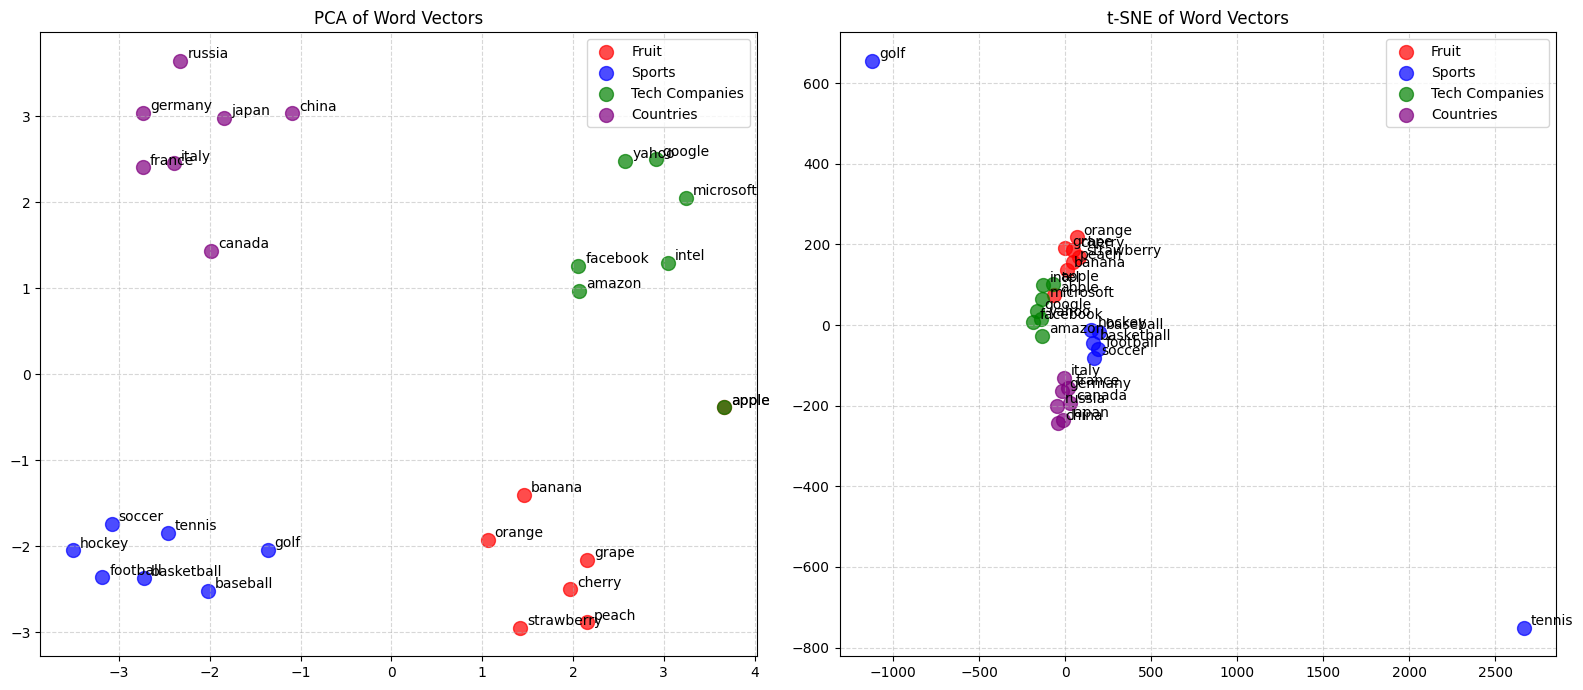

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Define groups of words to visualize semantic clustering
word_groups = {
    'Fruit': ['apple', 'banana', 'orange', 'cherry', 'grape', 'strawberry', 'peach'],
    'Sports': ['soccer', 'basketball', 'tennis', 'baseball', 'golf', 'hockey', 'football'],
    'Tech Companies': ['google', 'microsoft', 'facebook', 'apple', 'yahoo', 'amazon', 'intel'],
    'Countries': ['russia', 'france', 'china', 'japan', 'germany', 'canada', 'italy']
}

# Flatten words list and track their corresponding category label
words = []
categories = []
for category, word_list in word_groups.items():
    for w in word_list:
        if w in glove.stoi:
            words.append(w)
            categories.append(category)

# Retrieve GloVe vectors
vectors = np.array([get_word(w).numpy() for w in words])

# Run PCA (2D)
pca = PCA(n_components=2, random_state=42)
pca_results = pca.fit_transform(vectors)

# Run t-SNE (2D)
# perplexity is set low because our dataset of words is small
tsne = TSNE(n_components=2, perplexity=5, random_state=42, max_iter=1000)
tsne_results = tsne.fit_transform(vectors)

# Setup plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))
colors = {'Fruit': 'red', 'Sports': 'blue', 'Tech Companies': 'green', 'Countries': 'purple'}

# Plot PCA
for cat in word_groups.keys():
    indices = [i for i, c in enumerate(categories) if c == cat]
    ax1.scatter(pca_results[indices, 0], pca_results[indices, 1], label=cat, c=colors[cat], s=100, alpha=0.7)

for i, word in enumerate(words):
    ax1.annotate(word, (pca_results[i, 0], pca_results[i, 1]), xytext=(5, 2), textcoords='offset points', fontsize=10)

ax1.set_title('PCA of Word Vectors')
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend()

# Plot t-SNE
for cat in word_groups.keys():
    indices = [i for i, c in enumerate(categories) if c == cat]
    ax2.scatter(tsne_results[indices, 0], tsne_results[indices, 1], label=cat, c=colors[cat], s=100, alpha=0.7)

for i, word in enumerate(words):
    ax2.annotate(word, (tsne_results[i, 0], tsne_results[i, 1]), xytext=(5, 2), textcoords='offset points', fontsize=10)

ax2.set_title('t-SNE of Word Vectors')
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend()

plt.tight_layout()
plt.show()

### Effect of Perplexity on t-SNE

Perplexity loosely balances attention between local and global aspects of your data. It is roughly a guess about the number of close neighbors each point has.

Let's visualize the same set of word vectors using different perplexity values (`2`, `5`, `10`, and `20`) to see how the topology changes.

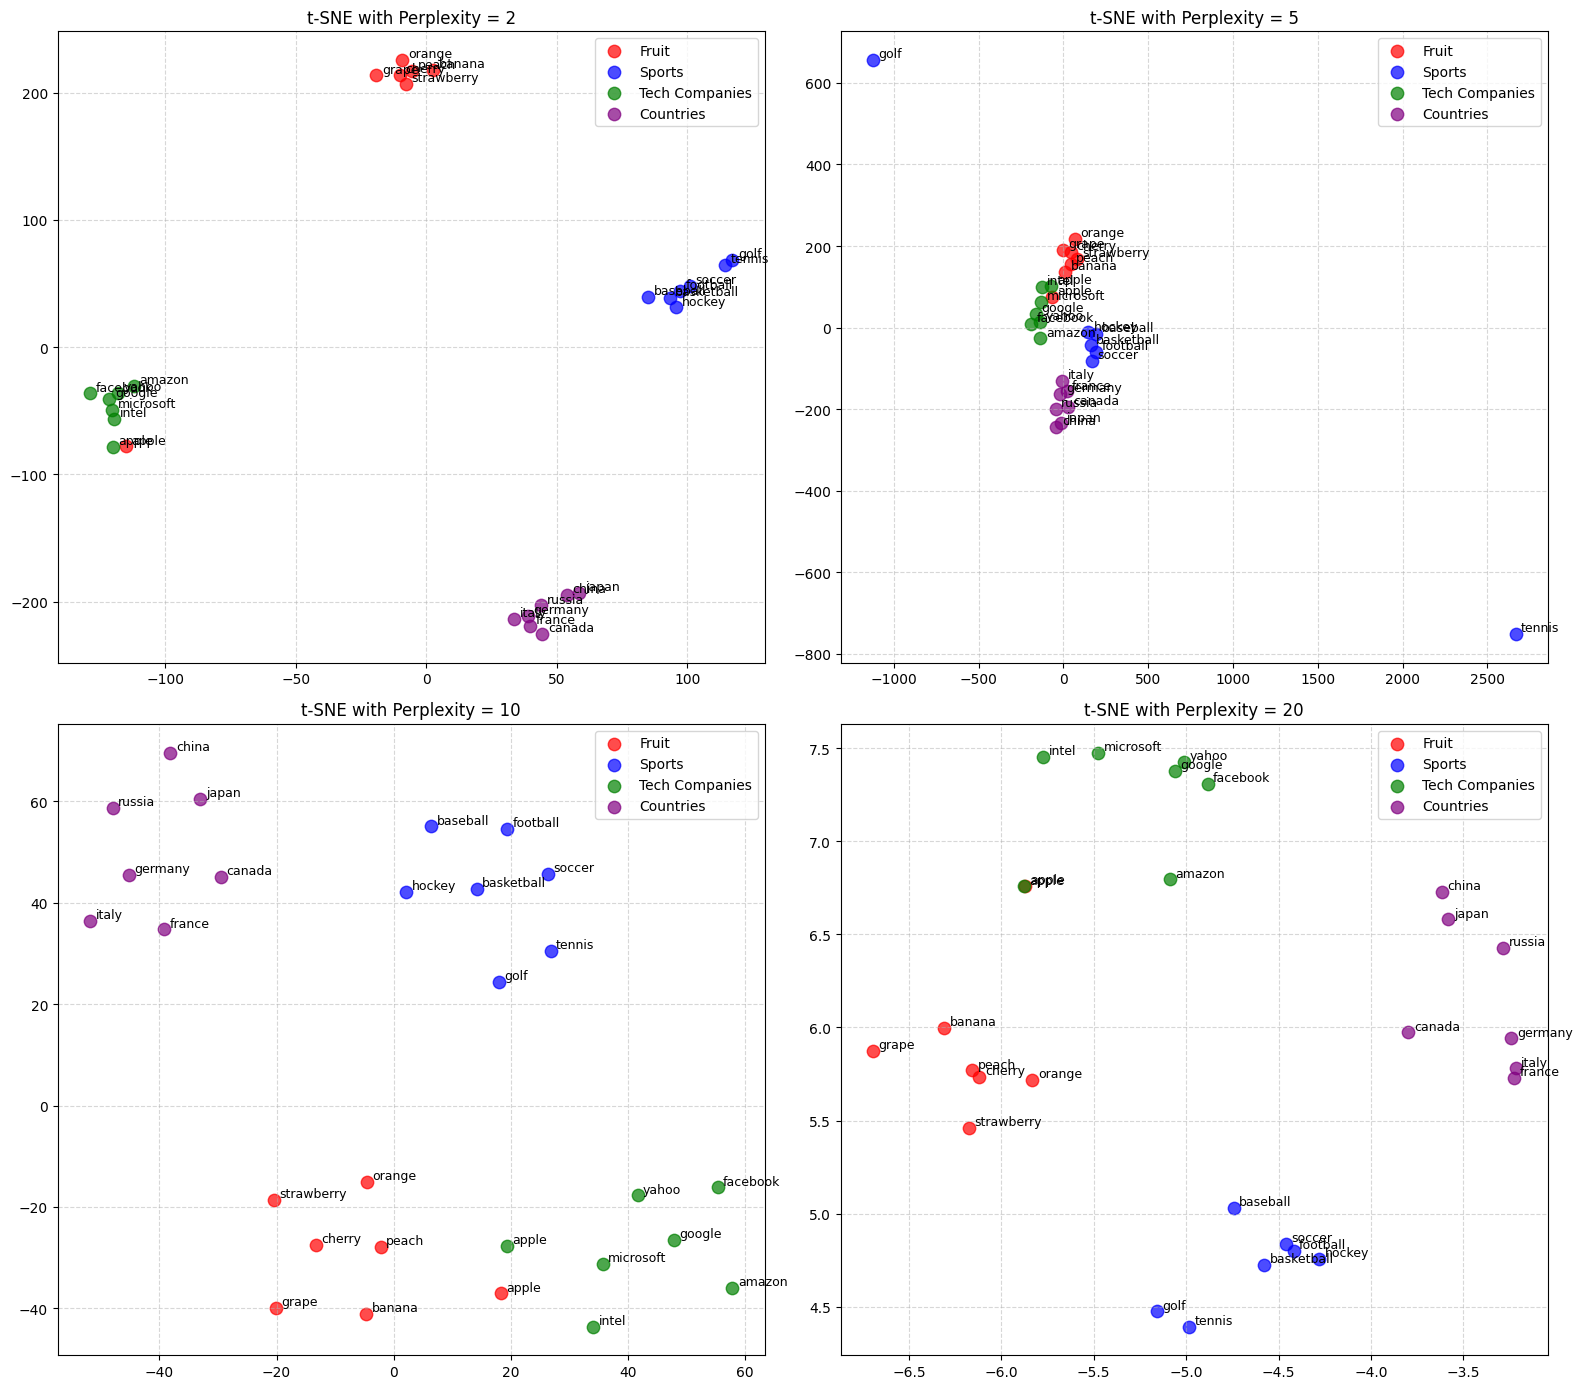

In [14]:
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

# We will test four different perplexities
perplexities = [2, 5, 10, 20]
fig, axes = plt.subplots(2, 2, figsize=(16, 14))
axes = axes.ravel()

colors = {'Fruit': 'red', 'Sports': 'blue', 'Tech Companies': 'green', 'Countries': 'purple'}

for i, perp in enumerate(perplexities):
    # Initialize and run t-SNE
    tsne_model = TSNE(n_components=2, perplexity=perp, random_state=42, max_iter=1000)
    results = tsne_model.fit_transform(vectors)

    # Plot clusters
    for cat in word_groups.keys():
        indices = [idx for idx, c in enumerate(categories) if c == cat]
        axes[i].scatter(results[indices, 0], results[indices, 1], label=cat, c=colors[cat], s=80, alpha=0.7)

    # Annotate points with words
    for idx, word in enumerate(words):
        axes[i].annotate(word, (results[idx, 0], results[idx, 1]), xytext=(4, 2), textcoords='offset points', fontsize=9)

    axes[i].set_title(f't-SNE with Perplexity = {perp}')
    axes[i].grid(True, linestyle='--', alpha=0.5)
    axes[i].legend()

plt.tight_layout()
plt.show()

### Testing Word Clusters at Scale

To observe how dimensionality reduction scales, let's expand our categories to include more words and additional semantic groups (e.g., Animals, Vehicles, Occupations, and Colors).

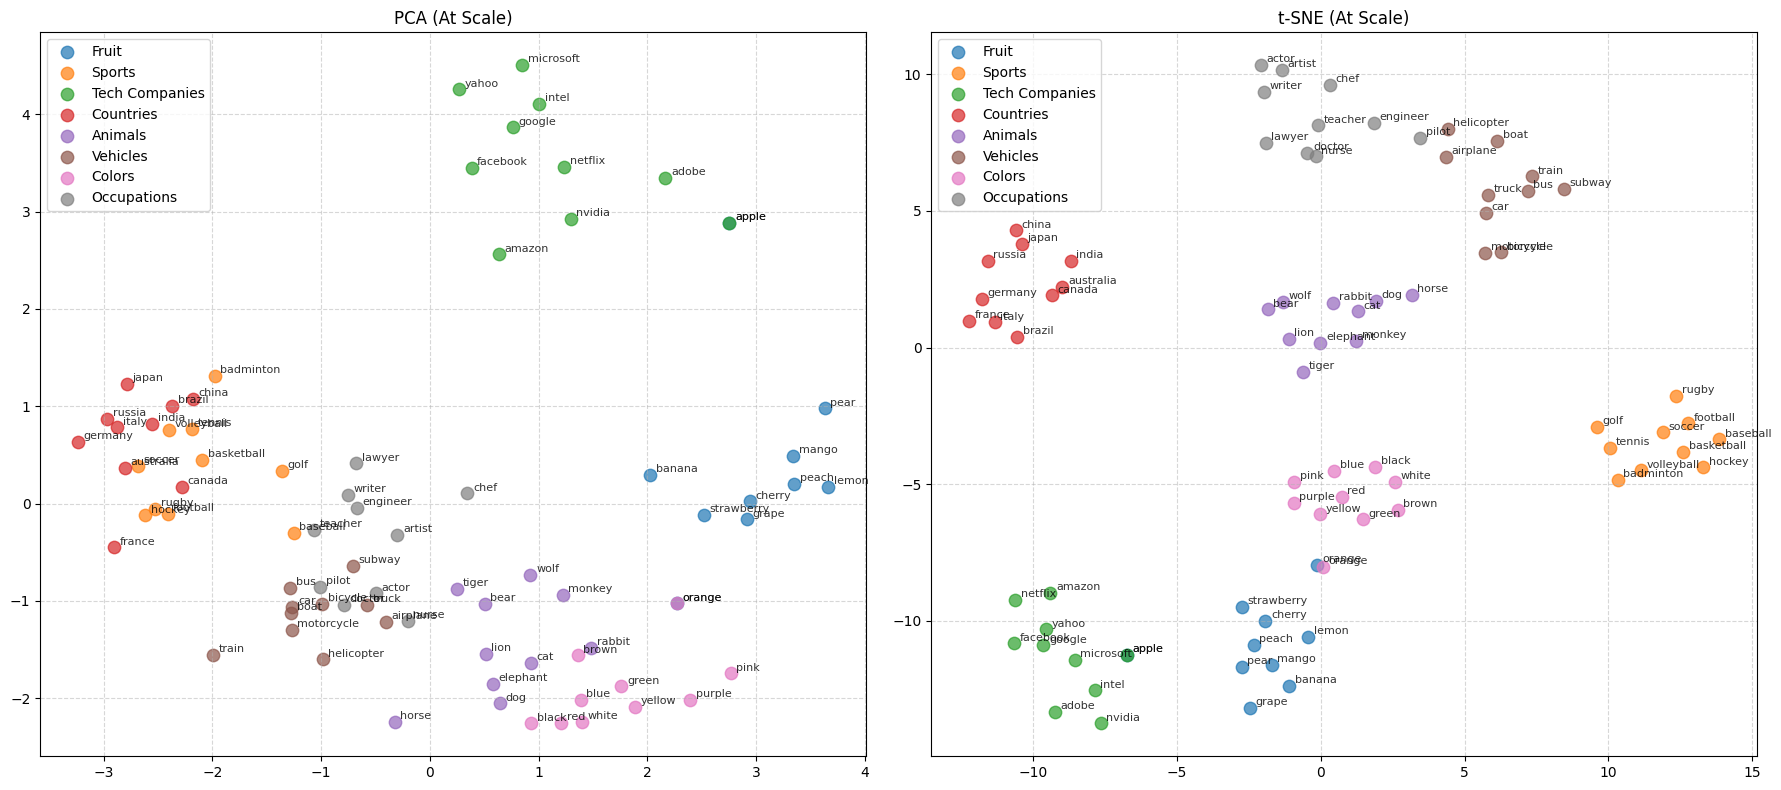

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Expanded word groups dictionary representing 8 distinct categories
large_word_groups = {
    'Fruit': ['apple', 'banana', 'orange', 'cherry', 'grape', 'strawberry', 'peach', 'lemon', 'pear', 'mango'],
    'Sports': ['soccer', 'basketball', 'tennis', 'baseball', 'golf', 'hockey', 'football', 'rugby', 'volleyball', 'badminton'],
    'Tech Companies': ['google', 'microsoft', 'facebook', 'apple', 'yahoo', 'amazon', 'intel', 'netflix', 'nvidia', 'adobe'],
    'Countries': ['russia', 'france', 'china', 'japan', 'germany', 'canada', 'italy', 'brazil', 'india', 'australia'],
    'Animals': ['dog', 'cat', 'lion', 'tiger', 'elephant', 'bear', 'rabbit', 'monkey', 'horse', 'wolf'],
    'Vehicles': ['car', 'truck', 'motorcycle', 'airplane', 'train', 'boat', 'bicycle', 'bus', 'helicopter', 'subway'],
    'Colors': ['red', 'blue', 'green', 'yellow', 'purple', 'orange', 'black', 'white', 'pink', 'brown'],
    'Occupations': ['doctor', 'teacher', 'engineer', 'artist', 'lawyer', 'nurse', 'writer', 'chef', 'pilot', 'actor']
}

# Flatten lists and track categories
large_words = []
large_categories = []
for category, word_list in large_word_groups.items():
    for w in word_list:
        if w in glove.stoi:
            large_words.append(w)
            large_categories.append(category)

# Retrieve GloVe vectors
large_vectors = np.array([get_word(w).numpy() for w in large_words])

# Run PCA (2D)
pca_large = PCA(n_components=2, random_state=42)
pca_large_results = pca_large.fit_transform(large_vectors)

# Run t-SNE (2D) - perplexity set to 15 to handle the larger sample size
tsne_large = TSNE(n_components=2, perplexity=15, random_state=42, max_iter=1000)
tsne_large_results = tsne_large.fit_transform(large_vectors)

# Setup plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8))
cmap = plt.get_cmap('tab10')
colors = {cat: cmap(i) for i, cat in enumerate(large_word_groups.keys())}

# Plot PCA
for cat in large_word_groups.keys():
    indices = [i for i, c in enumerate(large_categories) if c == cat]
    ax1.scatter(pca_large_results[indices, 0], pca_large_results[indices, 1], label=cat, color=colors[cat], s=80, alpha=0.7)

for i, word in enumerate(large_words):
    ax1.annotate(word, (pca_large_results[i, 0], pca_large_results[i, 1]), xytext=(4, 2), textcoords='offset points', fontsize=8, alpha=0.8)

ax1.set_title('PCA (At Scale)')
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend()

# Plot t-SNE
for cat in large_word_groups.keys():
    indices = [i for i, c in enumerate(large_categories) if c == cat]
    ax2.scatter(tsne_large_results[indices, 0], tsne_large_results[indices, 1], label=cat, color=colors[cat], s=80, alpha=0.7)

for i, word in enumerate(large_words):
    ax2.annotate(word, (tsne_large_results[i, 0], tsne_large_results[i, 1]), xytext=(4, 2), textcoords='offset points', fontsize=8, alpha=0.8)

ax2.set_title('t-SNE (At Scale)')
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend()

plt.tight_layout()
plt.show()

### Quantifying Cluster Separation with Silhouette Score

Let's calculate the Silhouette Score to objectively measure how well-defined our 8 semantic clusters are when projected into 2D space using PCA versus t-SNE.

In [16]:
from sklearn.metrics import silhouette_score

# Compute Silhouette Scores for both 2D embeddings
sil_score_pca = silhouette_score(pca_large_results, large_categories)
sil_score_tsne = silhouette_score(tsne_large_results, large_categories)

print("=== Cluster Separation Metrics (Silhouette Score) ===")
print(f"PCA (2D) Silhouette Score   : {sil_score_pca:.4f}")
print(f"t-SNE (2D) Silhouette Score : {sil_score_tsne:.4f}")

# Interpretation
if sil_score_tsne > sil_score_pca:
    print("\nt-SNE yields a higher silhouette score, indicating that its non-linear local neighborhood preservation creates much tighter, more distinct semantic clusters in 2D space.")
else:
    print("\nPCA yields a higher silhouette score, suggesting more globally consistent cluster configurations in this specific 2D linear projection.")

=== Cluster Separation Metrics (Silhouette Score) ===
PCA (2D) Silhouette Score   : 0.2619
t-SNE (2D) Silhouette Score : 0.6167

t-SNE yields a higher silhouette score, indicating that its non-linear local neighborhood preservation creates much tighter, more distinct semantic clusters in 2D space.


### Comparing with UMAP Dimensionality Reduction

To see how UMAP compares to PCA and t-SNE, we'll install `umap-learn`, project our large word vectors into 2D space, visualize the clusters, and measure its silhouette score.

In [17]:
!pip install umap-learn

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


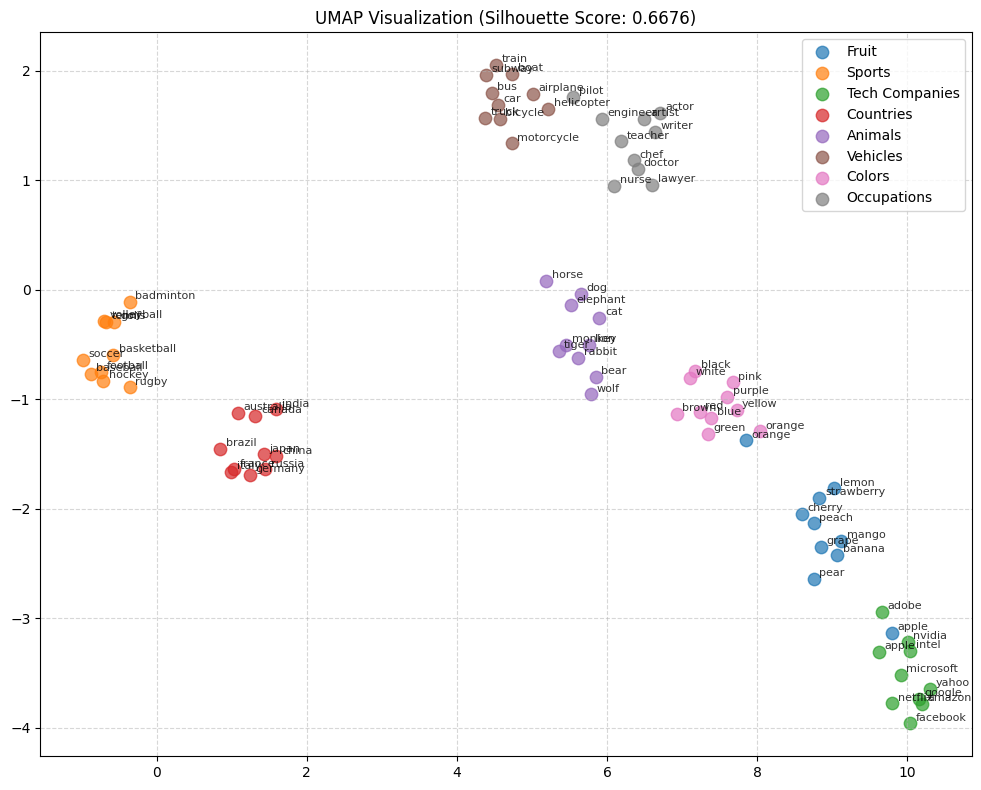

=== Updated Cluster Separation Metrics ===
PCA (2D) Silhouette Score   : 0.2619
t-SNE (2D) Silhouette Score : 0.6167
UMAP (2D) Silhouette Score  : 0.6676


In [18]:
import umap
import matplotlib.pyplot as plt

# Run UMAP (2D) - n_neighbors balances local vs global structures similarly to perplexity
umap_model = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42)
umap_large_results = umap_model.fit_transform(large_vectors)

# Calculate Silhouette Score for UMAP
sil_score_umap = silhouette_score(umap_large_results, large_categories)

# Setup Plot
plt.figure(figsize=(10, 8))
cmap = plt.get_cmap('tab10')
colors = {cat: cmap(i) for i, cat in enumerate(large_word_groups.keys())}

for cat in large_word_groups.keys():
    indices = [i for i, c in enumerate(large_categories) if c == cat]
    plt.scatter(umap_large_results[indices, 0], umap_large_results[indices, 1], label=cat, color=colors[cat], s=80, alpha=0.7)

for i, word in enumerate(large_words):
    plt.annotate(word, (umap_large_results[i, 0], umap_large_results[i, 1]), xytext=(4, 2), textcoords='offset points', fontsize=8, alpha=0.8)

plt.title(f'UMAP Visualization (Silhouette Score: {sil_score_umap:.4f})')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

print("=== Updated Cluster Separation Metrics ===")
print(f"PCA (2D) Silhouette Score   : {sil_score_pca:.4f}")
print(f"t-SNE (2D) Silhouette Score : {sil_score_tsne:.4f}")
print(f"UMAP (2D) Silhouette Score  : {sil_score_umap:.4f}")

### Exploring UMAP's `n_neighbors` Parameter

Let's evaluate UMAP using different values of `n_neighbors` (`2`, `5`, `15`, and `50`) to analyze how it structures our scaled dataset of 80 words.

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


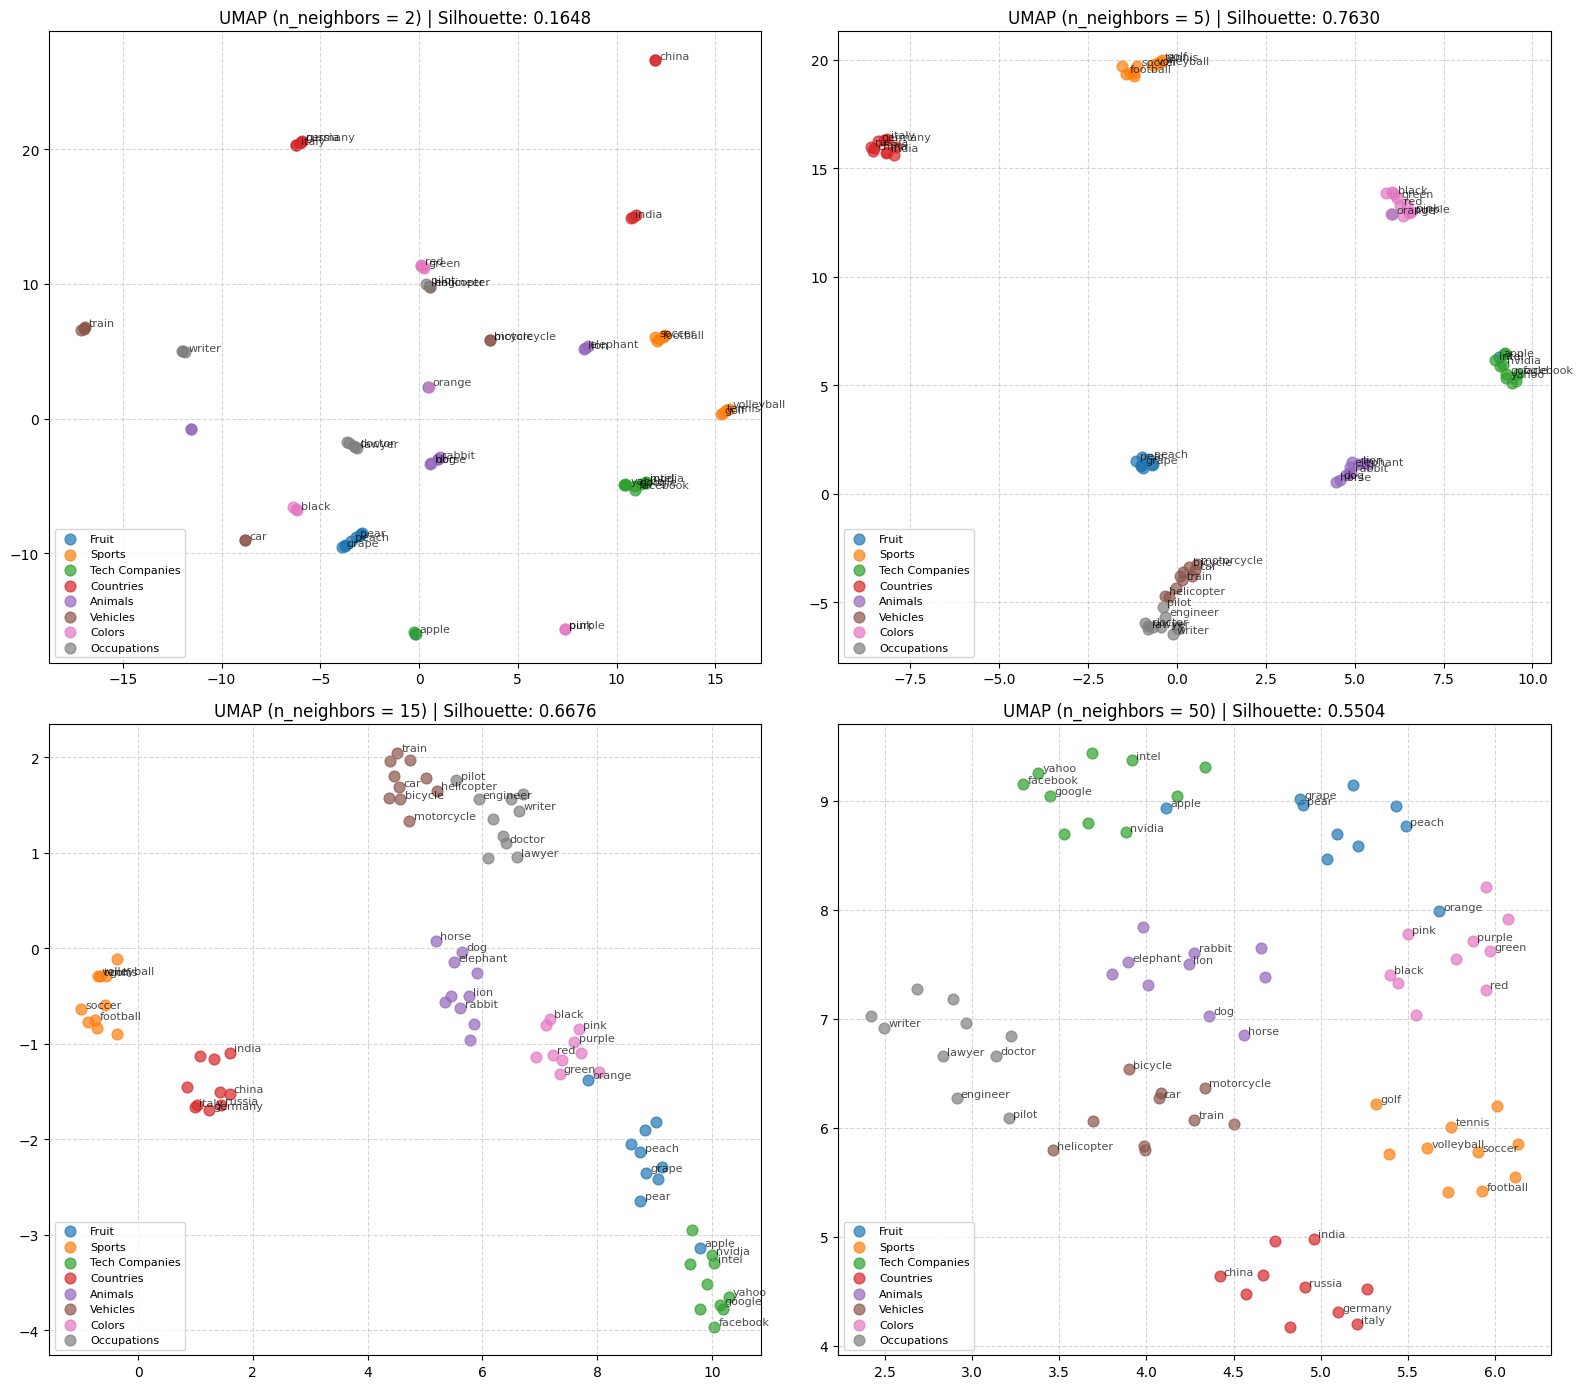

In [19]:
import matplotlib.pyplot as plt
import umap
from sklearn.metrics import silhouette_score

# Define the n_neighbors values to evaluate
n_neighbors_list = [2, 5, 15, 50]
fig, axes = plt.subplots(2, 2, figsize=(16, 14))
axes = axes.ravel()

cmap = plt.get_cmap('tab10')
colors = {cat: cmap(i) for i, cat in enumerate(large_word_groups.keys())}

for i, n_neigh in enumerate(n_neighbors_list):
    # Initialize and run UMAP
    umap_temp = umap.UMAP(n_neighbors=n_neigh, min_dist=0.1, n_components=2, random_state=42)
    results = umap_temp.fit_transform(large_vectors)

    # Calculate Silhouette Score
    score = silhouette_score(results, large_categories)

    # Plot clusters
    for cat in large_word_groups.keys():
        indices = [idx for idx, c in enumerate(large_categories) if c == cat]
        axes[i].scatter(results[indices, 0], results[indices, 1], label=cat, color=colors[cat], s=60, alpha=0.7)

    # Annotate points with subset of words to avoid excessive clutter
    for idx, word in enumerate(large_words):
        if idx % 2 == 0:  # Display every second word to keep plots readable
            axes[i].annotate(word, (results[idx, 0], results[idx, 1]), xytext=(3, 1), textcoords='offset points', fontsize=8, alpha=0.7)

    axes[i].set_title(f'UMAP (n_neighbors = {n_neigh}) | Silhouette: {score:.4f}')
    axes[i].grid(True, linestyle='--', alpha=0.5)
    axes[i].legend(loc='lower left', fontsize=8)

plt.tight_layout()
plt.show()

### Comparing Runtime Efficiency: UMAP vs. t-SNE

Let's quantitatively measure the time it takes for both t-SNE and UMAP to perform dimensionality reduction on our scaled set of vectors.

In [20]:
import time
from sklearn.manifold import TSNE
import umap

# Measure execution time for t-SNE
start_time = time.time()
tsne_temp = TSNE(n_components=2, perplexity=15, random_state=42, max_iter=1000)
_ = tsne_temp.fit_transform(large_vectors)
tsne_duration = time.time() - start_time

# Measure execution time for UMAP
start_time = time.time()
umap_temp = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42)
_ = umap_temp.fit_transform(large_vectors)
umap_duration = time.time() - start_time

print("=== Execution Time Comparison ===")
print(f"t-SNE Execution Time : {tsne_duration:.4f} seconds")
print(f"UMAP Execution Time   : {umap_duration:.4f} seconds")
print(f"UMAP is {tsne_duration / umap_duration:.2f}x faster than t-SNE on this dataset.")

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


=== Execution Time Comparison ===
t-SNE Execution Time : 1.1582 seconds
UMAP Execution Time   : 0.2276 seconds
UMAP is 5.09x faster than t-SNE on this dataset.
